Amazon Alexa Sentiment Analysis Using Machine Learning

Developed a sentiment analysis system to classify Amazon Alexa customer 
reviews into positive and negative feedback using Machine Learning algorithms.
Performed data cleaning, preprocessing, exploratory data analysis (EDA), 
and text vectorization using TF-IDF. Implemented and evaluated Random Forest,
XGBoost, Decision Tree, and Support Vector Machine (SVM) models using Python 
and Scikit-learn.


In [ ]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [22]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#import warnings
#warnings.filterwarnings('ignore')


In [23]:
%pip install nltk wordcloud xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
from wordcloud import WordCloud
import re
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
import pickle

In [25]:
df = pd.read_csv("amazon_alexa.tsv",sep="\t")
df.head()

,rating,date,variation,verified_reviews,feedback
0,5,31-Jul-18,Charcoal Fabric,Love my Echo!,1.0
1,5,31-Jul-18,Charcoal Fabric,Loved it!,1.0
2,4,31-Jul-18,Walnut Finish,"Sometimes while playing a game, you can answer...",1.0
3,5,31-Jul-18,Charcoal Fabric,I have had a lot of fun with this thing. My 4 ...,1.0
4,5,31-Jul-18,Charcoal Fabric,Music,1.0


In [26]:
df.tail()

,rating,date,variation,verified_reviews,feedback
3145,5,30-Jul-18,Black Dot,"Perfect for kids, adults and everyone in betwe...",1.0
3146,5,30-Jul-18,Black Dot,"Listening to music, searching locations, check...",1.0
3147,5,30-Jul-18,Black Dot,"I do love these things, i have them running my...",1.0
3148,5,30-Jul-18,White Dot,Only complaint I have is that the sound qualit...,1.0
3149,4,29-Jul-18,Black Dot,Good,1.0


In [27]:
df.shape

(3150, 5)

In [28]:
df['feedback'].unique()

array([ 1.,  0., nan])

In [29]:
df["feedback"].value_counts()

feedback
1.0    2892
0.0     257
Name: count, dtype: int64

In [30]:
class_0 = df[df["feedback"]==0]
class_1 = df[df['feedback']==1]
class_0_oversampled = class_0.sample(len(class_1)//2, replace = True, random_state = 42 ) 
class_1_undersampled = class_1.sample(len(class_0_oversampled),random_state = 42)
new_df = pd.concat([class_0_oversampled,class_1_undersampled]).reset_index(drop = True)

In [31]:
new_df.shape

(2892, 5)

In [32]:
new_df.columns

Index(['rating', 'date', 'variation', 'verified_reviews', 'feedback'],
      dtype='str')

In [33]:
new_df['feedback'].value_counts()

feedback
0.0    1446
1.0    1446
Name: count, dtype: int64

In [34]:
new_df.isnull().sum()

rating              0
date                0
variation           0
verified_reviews    1
feedback            0
dtype: int64

In [35]:
new_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2892 entries, 0 to 2891
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   rating            2892 non-null   int64  
 1   date              2892 non-null   str    
 2   variation         2892 non-null   str    
 3   verified_reviews  2891 non-null   str    
 4   feedback          2892 non-null   float64
dtypes: float64(1), int64(1), str(3)
memory usage: 113.1 KB


In [36]:
new_df[new_df['verified_reviews'].isna()==True]

,rating,date,variation,verified_reviews,feedback
572,2,29-Jun-18,White,NaN,0.0


In [37]:
new_df.dropna(
    inplace = True
)

C:\Users\HP\AppData\Local\Temp\ipykernel_8816\705822957.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  new_df.dropna(


In [38]:
new_df.isnull().sum()

rating              0
date                0
variation           0
verified_reviews    0
feedback            0
dtype: int64

In [39]:
new_df.shape

(2891, 5)

In [40]:
new_df["length"] = new_df["verified_reviews"].apply(len)

In [41]:
new_df.head()

,rating,date,variation,verified_reviews,feedback,length
0,1,22-Jul-18,Black Spot,I own 3 of these... amazon is ignoring its cu...,0.0,525
1,1,19-Jul-18,Black Spot,Can't turn of &#34;things to try&#34; on the s...,0.0,195
2,1,28-Jul-18,Charcoal Fabric,Alexa hardly came on..,0.0,22
3,1,30-Jul-18,Configuration: Fire TV Stick,,0.0,1
4,2,22-Jul-18,White,"Initially, this echo dot worked very well. Ove...",0.0,272


In [42]:
print(f"'verified_reviews' column value: {new_df.iloc[10]['verified_reviews']}") #Original value
print(f"Length of review : {len(new_df.iloc[10]['verified_reviews'])}") #Length of review using len()
print(f"'length' column value : {new_df.iloc[10]['length']}") 

'verified_reviews' column value: Terrible. Stopped working after one day.
Length of review : 40
'length' column value : 40


In [43]:
new_df.dtypes

rating                int64
date                    str
variation               str
verified_reviews        str
feedback            float64
length                int64
dtype: object

In [44]:
print(f"rating column value count :\n {new_df["rating"].value_counts()}")

rating column value count :
 rating
5    1151
1     892
2     553
4     217
3      78
Name: count, dtype: int64


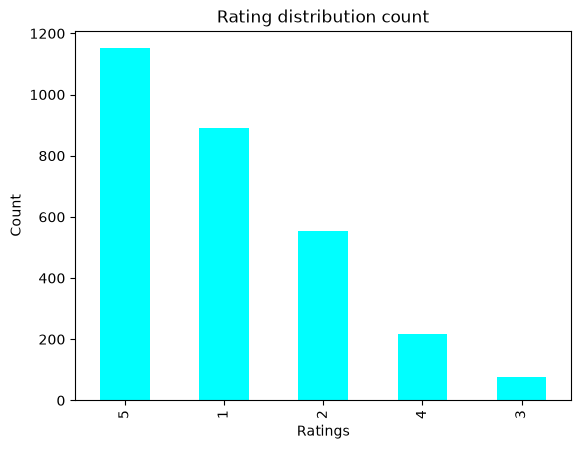

In [45]:
new_df['rating'].value_counts().plot.bar(color = 'cyan')
plt.title('Rating distribution count')
plt.xlabel('Ratings')
plt.ylabel('Count')
plt.show()

<Axes: >

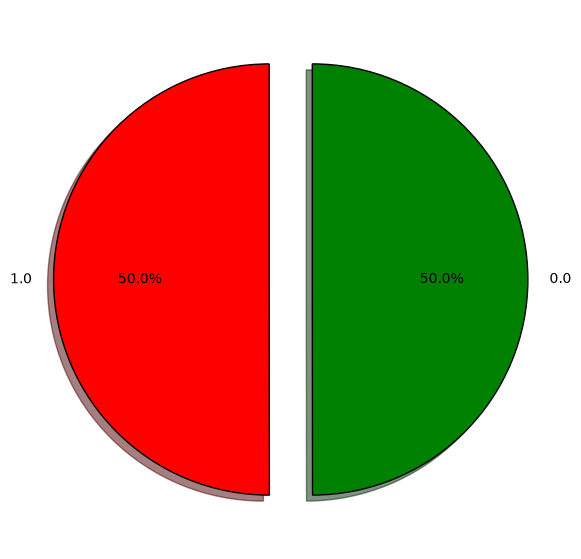

In [46]:
fig = plt.figure(figsize=(7,7))

colors = ('red', 'green')

wp = {'linewidth':1, "edgecolor":'black'}

tags =new_df['feedback'].value_counts()/new_df.shape[0]
explode=(0.1,0.1)



tags.plot(kind='pie', autopct="%1.1f%%", shadow=True, colors=colors, startangle=90, wedgeprops=wp, explode=explode, label='Percentage wise distrubution of feedback')

In [47]:
new_df[new_df['feedback'] == 0]['rating'].value_counts()

rating
1    892
2    553
Name: count, dtype: int64

In [48]:
new_df[new_df['feedback']==1]['rating'].value_counts()

rating
5    1151
4     217
3      78
Name: count, dtype: int64

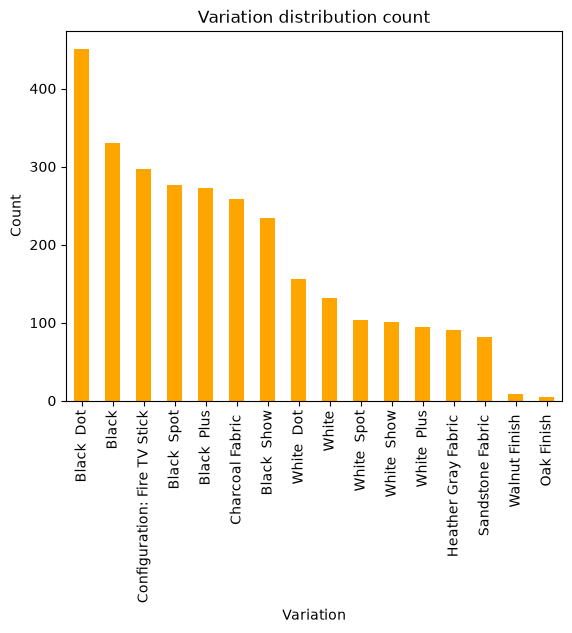

In [49]:
new_df['variation'].value_counts().plot.bar(color = 'orange')
plt.title('Variation distribution count')
plt.xlabel('Variation')
plt.ylabel('Count')
plt.show()

In [50]:
new_df['length'].describe()

count    2891.000000
mean      171.312695
std       211.098623
min         1.000000
25%        36.500000
50%       104.000000
75%       215.000000
max      1954.000000
Name: length, dtype: float64

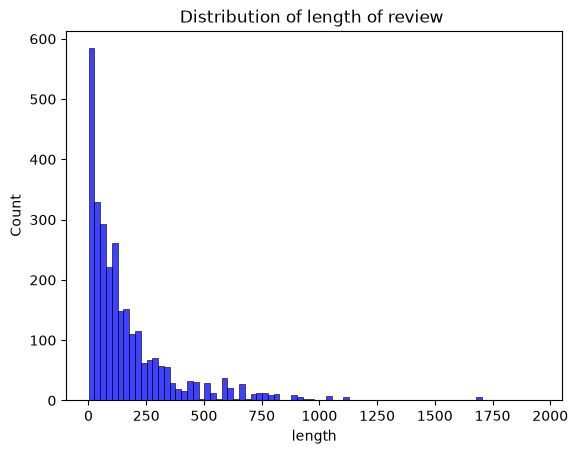

In [51]:
sns.histplot(new_df['length'],color = 'blue')
plt.title("Distribution of length of review ")
plt.show()

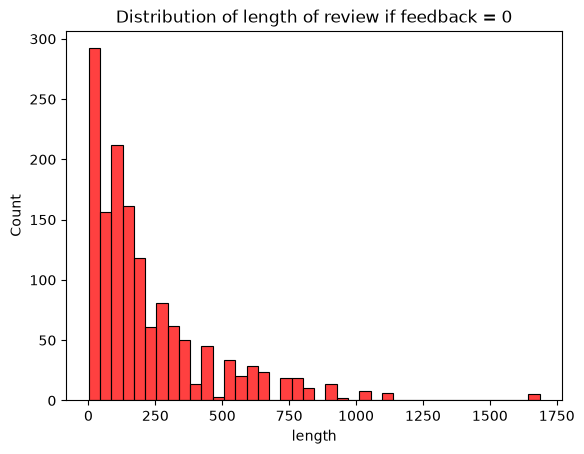

In [52]:
sns.histplot(new_df[new_df['feedback']==0]['length'],color = 'red')
plt.title("Distribution of length of review if feedback = 0")
plt.show()

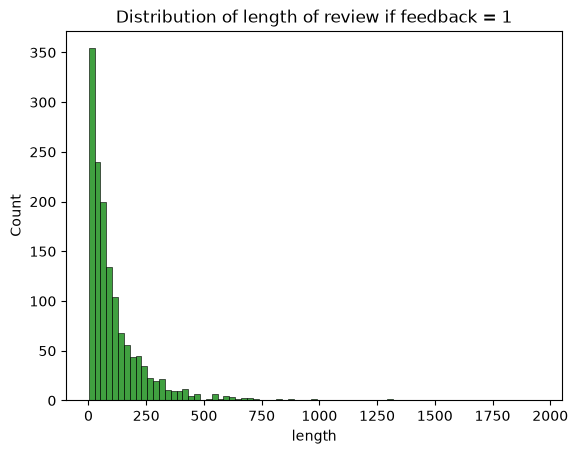

In [53]:
sns.histplot(new_df[new_df['feedback']==1]['length'],color='green')
plt.title('Distribution of length of review if feedback = 1')
plt.show()

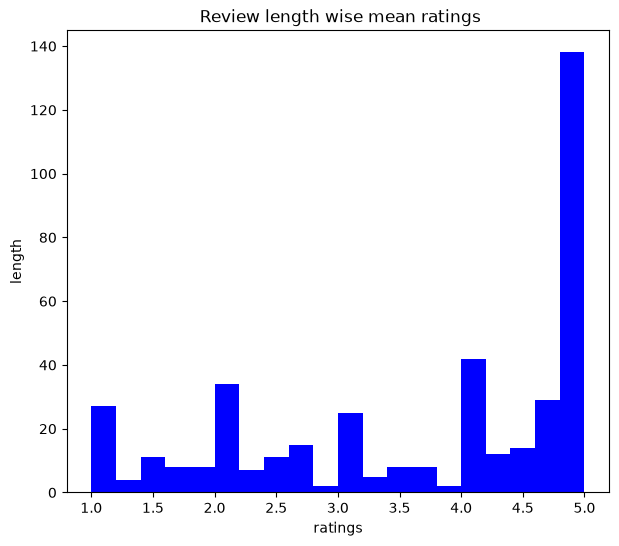

In [54]:
new_df.groupby('length')['rating'].mean().plot.hist(color = 'blue', figsize=(7, 6), bins = 20)
plt.title(" Review length wise mean ratings")
plt.xlabel('ratings')
plt.ylabel('length')
plt.show()

In [55]:
! pip install scikit-learn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


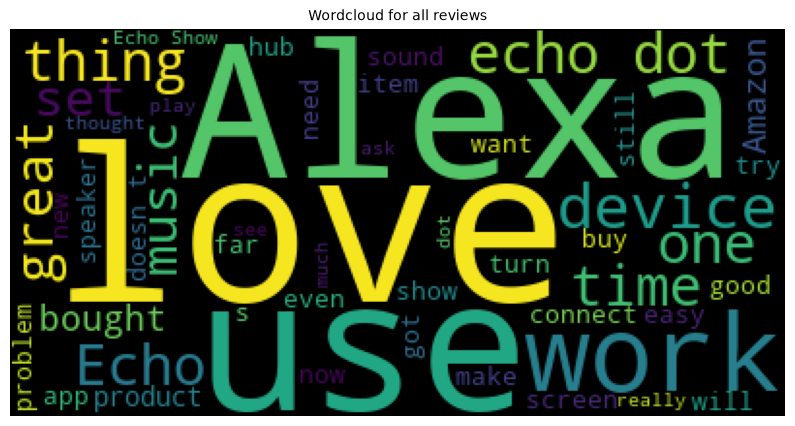

In [56]:
reviews = " ".join([review for review in new_df['verified_reviews']])                       
wc = WordCloud(background_color='black', max_words=50)

plt.figure(figsize=(10,10))
plt.imshow(wc.generate(reviews))
plt.title('Wordcloud for all reviews', fontsize=10)
plt.axis('off')
plt.show()

In [57]:
neg_reviews = " ".join([review for review in new_df[new_df['feedback'] == 0]['verified_reviews']])
neg_reviews = neg_reviews.lower().split()

pos_reviews = " ".join([review for review in new_df[new_df['feedback'] == 1]['verified_reviews']])
pos_reviews = pos_reviews.lower().split()

unique_negative = [x for x in neg_reviews if x not in pos_reviews]
unique_negative = " ".join(unique_negative)

unique_positive = [x for x in pos_reviews if x not in neg_reviews]
unique_positive = " ".join(unique_positive)


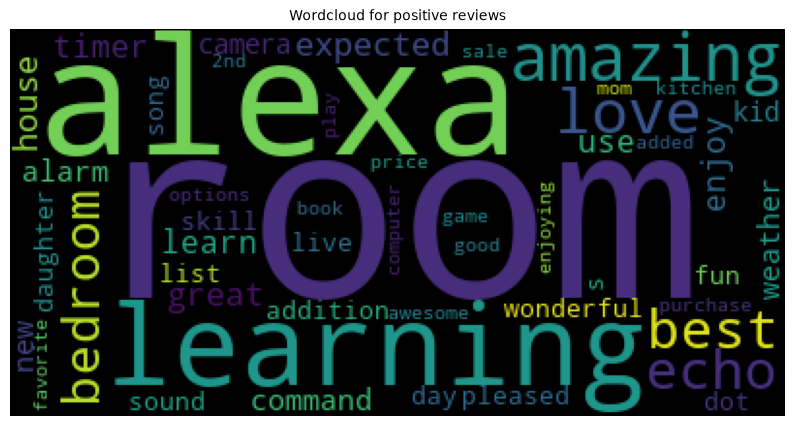

In [58]:
wc = WordCloud(background_color='black', max_words=50)

plt.figure(figsize=(10,10))
plt.imshow(wc.generate(unique_positive))
plt.title('Wordcloud for positive reviews', fontsize=10)
plt.axis('off')
plt.show()

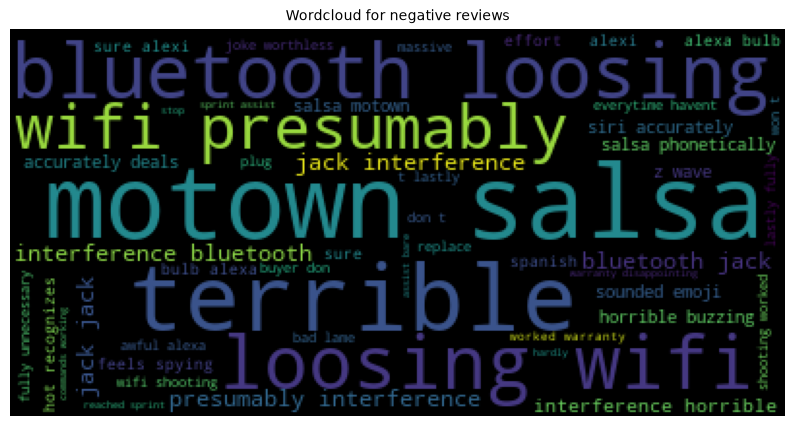

In [59]:
wc = WordCloud(background_color='black', max_words=50)

# Generate and plot wordcloud
plt.figure(figsize=(10,10))
plt.imshow(wc.generate(unique_negative))
plt.title('Wordcloud for negative reviews', fontsize=10)
plt.axis('off')
plt.show()

In [60]:
corpus = new_df['verified_reviews'].apply(lambda x: re.sub(r'[^a-zA-Z]', ' ', x).lower())
tfidf = TfidfVectorizer(max_features=3000, stop_words='english')
X = tfidf.fit_transform(corpus).toarray()
y = new_df['feedback']

In [61]:
pickle.dump(tfidf, open('tfidf.pkl', 'wb'))

In [62]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [63]:
pickle.dump(scaler, open('scaler.pkl','wb'))

## Random Forest

In [64]:
rf_model = RandomForestClassifier(
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    class_weight='balanced'
)
rf_model.fit(X_train_scaled, y_train)

# Evaluate
y_test_pred_rf = rf_model.predict(X_test_scaled)
print('Random Forest Classifier:')
print(classification_report(y_test, y_test_pred_rf))

Random Forest Classifier:
              precision    recall  f1-score   support

         0.0       0.90      0.76      0.83       289
         1.0       0.80      0.91      0.85       290

    accuracy                           0.84       579
   macro avg       0.85      0.84      0.84       579
weighted avg       0.85      0.84      0.84       579



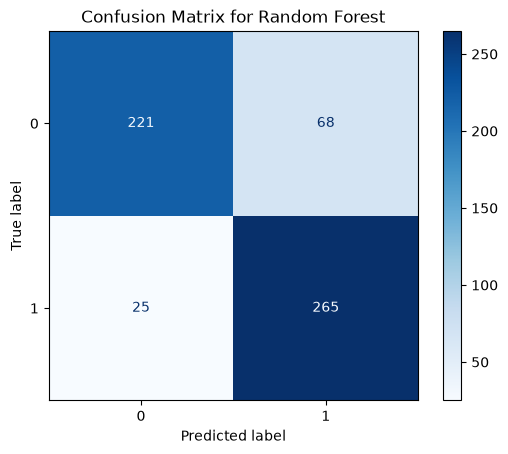

In [65]:
cm = confusion_matrix(y_test, y_test_pred_rf)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix for Random Forest")
plt.show()

In [66]:
pickle.dump(rf_model, open('rf_model.pkl', 'wb'))

In [67]:
print("Training Accuracy :", rf_model.score(X_train_scaled, y_train))
print("Testing Accuracy :", rf_model.score(X_test_scaled, y_test))

Training Accuracy : 0.8724048442906575
Testing Accuracy : 0.8393782383419689


In [68]:
accuracies = cross_val_score(estimator = rf_model, X = X_train_scaled, y = y_train, cv = 10) ##This code performs 10-fold Cross-Validation on your 
##Random Forest Classifier to evaluate how well the model performs across different portions of your training dataset.

print("Accuracy :",accuracies.mean())
print("Standard deviation :",accuracies.std())

Accuracy : 0.8429989550679207
Standard deviation : 0.017153563044085367


In [69]:
# Perform cross-validation
cv_scores = cross_val_score(rf_model,X_train_scaled, y_train, cv=5)
print(f"Cross-validation scores: {cv_scores}")
print(f"Mean cross-validation score:{cv_scores.mean()}")


Cross-validation scores: [0.83585313 0.86177106 0.85714286 0.82467532 0.80952381]
Mean cross-validation score:0.8377932362813573


## XGBoost

In [70]:
xgb_model = XGBClassifier(
    max_depth=10,
    learning_rate=0.1,
    n_estimators=100,
    random_state=42
)
xgb_model.fit(X_train_scaled, y_train)

# Evaluate
y_test_pred_xgb = xgb_model.predict(X_test_scaled)
print('XGBoost Classifier:')
print(classification_report(y_test, y_test_pred_xgb))

XGBoost Classifier:
              precision    recall  f1-score   support

         0.0       0.86      0.99      0.92       289
         1.0       0.99      0.83      0.90       290

    accuracy                           0.91       579
   macro avg       0.92      0.91      0.91       579
weighted avg       0.92      0.91      0.91       579



In [71]:
pickle.dump(xgb_model,open('xgb_model.pkl','wb'))

## Decision Tree 

In [72]:
dt_model = DecisionTreeClassifier(
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)
dt_model.fit(X_train_scaled, y_train)

# Evaluate
y_test_pred_dt = dt_model.predict(X_test_scaled)
print('Decision Tree Classifier:')
print(classification_report(y_test, y_test_pred_dt))

Decision Tree Classifier:
              precision    recall  f1-score   support

         0.0       0.72      1.00      0.84       289
         1.0       1.00      0.61      0.76       290

    accuracy                           0.80       579
   macro avg       0.86      0.81      0.80       579
weighted avg       0.86      0.80      0.80       579



In [73]:
pickle.dump(dt_model,open('dt_model.pkl', 'wb'))

## SVM

In [74]:
svm_model = SVC(kernel='linear', random_state=42)
svm_model.fit(X_train_scaled,y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [75]:
y_test_pred_svm  = svm_model.predict(X_test_scaled)
print('SVM:')
print(classification_report(y_test, y_test_pred_svm))

SVM:
              precision    recall  f1-score   support

         0.0       0.94      0.93      0.94       289
         1.0       0.93      0.94      0.94       290

    accuracy                           0.94       579
   macro avg       0.94      0.94      0.94       579
weighted avg       0.94      0.94      0.94       579



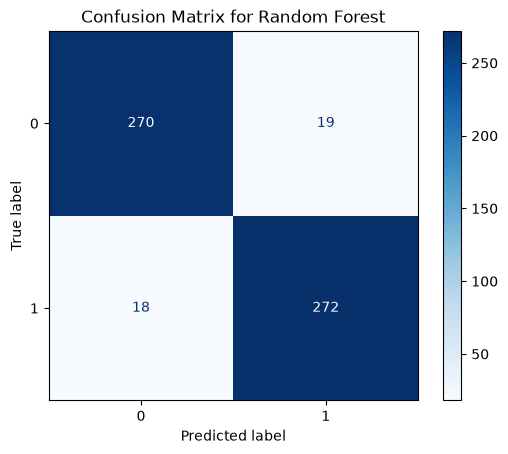

In [76]:
cm = confusion_matrix(y_test, y_test_pred_svm)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix for Random Forest")
plt.show()

In [77]:
pickle.dump(svm_model,open('svm_model.pkl', 'wb'))

In [78]:
import pandas as pd
import re
from sklearn.feature_extraction.text import TfidfVectorizer
import pickle

# Load the pickled models
svm_model = pickle.load(open('svm_model.pkl', 'rb'))
tfidf = pickle.load(open('tfidf.pkl', 'rb'))
scaler = pickle.load(open('scaler.pkl', 'rb'))

# Function for text preprocessing
def preprocess_text(review):
    if not isinstance(review, str):
        review = ''  
    review = re.sub(r'[^a-zA-Z]', ' ', review).lower()  
    return review

# Function for single inference (prediction)
def single_inference(verified_reviews):
   
    preprocessed_review = preprocess_text(verified_reviews)

    vectorized_features = tfidf.transform([preprocessed_review]).toarray()

    scaled_features = scaler.transform(vectorized_features)

    # Make prediction using the trained SVM model
    y_test_pred_nb = svm_model.predict(scaled_features)[0]

    # Map prediction to labels
    labels = {0:"Negative",1:"Positive"}  
    return labels[y_test_pred_nb]

# Function to load test data and make predictions
def test_model_on_csv(file_path):
    df = pd.read_csv(file_path)

    if 'verified_reviews' not in df.columns:
        print("The input file must contain 'verified_reviews' column.")
        return

    df['predicted_sentiment'] = (
        df['verified_reviews'].fillna('').apply(single_inference)
    )

    df.to_csv('predicted_reviews.csv', index=False)
    print("Predictions saved to 'predicted_reviews.csv'.")

# Run the function
test_model_on_csv("sample_reviews_for_testing.csv")

Predictions saved to 'predicted_reviews.csv'.
